<a href="https://colab.research.google.com/github/kylaivanona/TUGAS3_Kylaivanona-W.L/blob/main/Tugas3_Kylaivanona_W_L.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Load dataset dari URL GitHub (data terpisah menggunakan delimiter tab / '\t')
url = "https://raw.githubusercontent.com/ayyash-ayyub/RAT_dan_OER_FST_SD_UT_2025/main/cpa.csv"
df = pd.read_csv(url, sep="\t")

# Menampilkan 5 baris awal
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#Step2: lakukan Eksplorasi awal

In [4]:
# Ringkasan struktur data, tipe data, dan missing values
print("--- Informasi Data ---")
print(df.info())

print("\n--- Jumlah Missing Values ---")
print(df.isnull().sum())

print("\n--- Statistik Deskriptif ---")
df.describe()

--- Informasi Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchas

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


# Step 3: Identifikasi kolom numerik & kategori

In [5]:
# Memisahkan kolom berdasarkan tipe data
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Menghapus ID dan Dt_Customer dari fitur numerik/kategori jika ada
if "ID" in num_cols:
    num_cols.remove("ID")
if "Dt_Customer" in cat_cols:
    cat_cols.remove("Dt_Customer")

print("Kolom Kategori:", cat_cols)
print("Kolom Numerik:", num_cols)

Kolom Kategori: ['Education', 'Marital_Status']
Kolom Numerik: ['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


# Step 4: Imputasi missing value

In [27]:
# Imputasi nilai hilang pada fitur numerik menggunakan median
imputer_num = SimpleImputer(strategy="median")
df_num_imputed = pd.DataFrame(
    imputer_num.fit_transform(df[num_cols]), columns=num_cols
)

# Imputasi nilai hilang pada fitur kategori (jika ada)
if len(cat_cols) > 0:
  imputer_cat = SimpleImputer(strategy="most_frequent")
  df_cat_imputed = pd.DataFrame(
      imputer_cat.fit_transform(df[cat_cols]), columns=cat_cols
  )
else:
  df_cat_imputed = df[cat_cols].copy()

# Cek kembali apakah masih ada nilai NaN
print(
    "Jumlah NaN pada data numerik setelah imputasi:",
    df_num_imputed.isnull().sum().sum(),
)

Jumlah NaN pada data numerik setelah imputasi: 0



# Step 5: Encoding fitur kategori

In [39]:
# Encoding fitur kategori
encoder = OneHotEncoder(sparse_output=False, drop="first")
encoded_cats = encoder.fit_transform(df_cat_imputed)
encoded_cat_df = pd.DataFrame(
    encoded_cats, columns=encoder.get_feature_names_out(cat_cols)
)

#Gabungkan data numerik & hasil encoding

In [29]:
# Penggabungan data numerik dan kategori hasil encoding
df_processed = pd.concat(
    [df[num_cols].reset_index(drop=True), encoded_cat_df.reset_index(drop=True)],
    axis=1,
)

df_processed.head()


,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,1957,58138.0,0,0,58,635,88,546,172,88,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1954,46344.0,1,1,38,11,1,6,2,1,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1965,71613.0,0,0,26,426,49,127,111,21,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1984,26646.0,1,0,26,11,4,20,10,3,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1981,58293.0,1,0,94,173,43,118,46,27,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


# Step 6: Scaling data

In [32]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_processed)

print("Matriks data setelah scaling (baris, kolom):", X_scaled.shape)
print("Apakah masih ada NaN pada X_scaled?", np.isnan(X_scaled).any())

Matriks data setelah scaling (baris, kolom): (2240, 36)
Apakah masih ada NaN pada X_scaled? False



# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

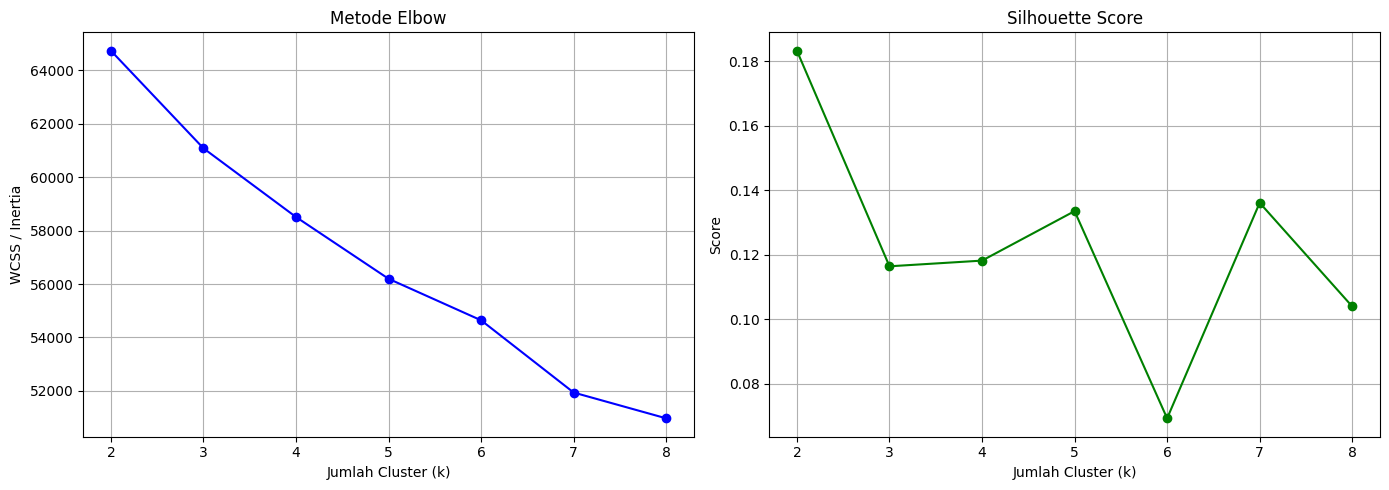

In [33]:
wcss = []
silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(X_scaled)

  wcss.append(kmeans.inertia_)
  # Menggunakan sampel agar perhitungan Silhouette score lebih efisien
  skor = silhouette_score(
      X_scaled, labels, sample_size=1500, random_state=42
  )
  silhouette_scores.append(skor)

# Visualisasi Elbow & Silhouette Score
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot Elbow Method
ax[0].plot(k_range, wcss, marker='o', color='b')
ax[0].set_title('Metode Elbow')
ax[0].set_xlabel('Jumlah Cluster (k)')
ax[0].set_ylabel('WCSS / Inertia')
ax[0].grid(True)

# Plot Silhouette Score
ax[1].plot(k_range, silhouette_scores, marker='o', color='g')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Jumlah Cluster (k)')
ax[1].set_ylabel('Score')
ax[1].grid(True)

plt.tight_layout()
plt.show()

# Step 8: Pilih k optimal dan klasterisasi

In [34]:
# Berdasarkan hasil analisis Elbow/Silhouette (umumnya k=3 atau k=4 optimal untuk dataset CPA)
optimal_k = 3

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Cluster"] = kmeans_final.fit_predict(X_scaled)

print(f"Klasterisasi selesai dengan k = {optimal_k}")
print(df["Cluster"].value_counts())

Klasterisasi selesai dengan k = 3
Cluster
1    1020
0     662
2     558
Name: count, dtype: int64


# Step 9: Visualisasi klaster dengan PCA 2D

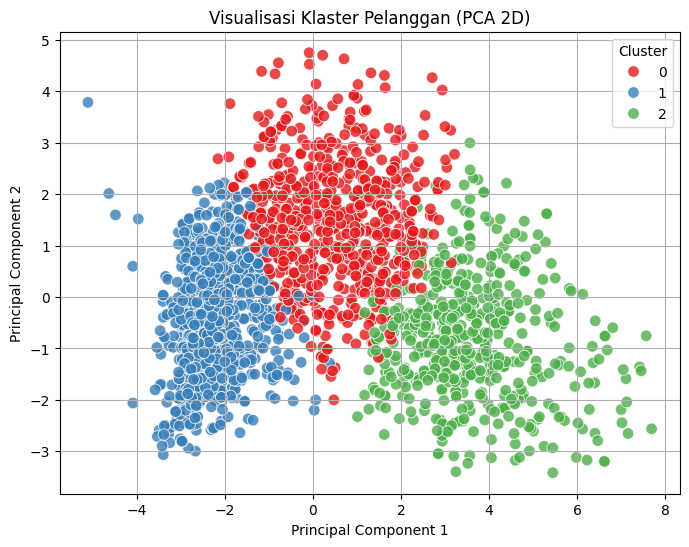

In [35]:
pca = PCA(n_components=2)
pca_features = pca.fit_transform(X_scaled)

df["PCA1"] = pca_features[:, 0]
df["PCA2"] = pca_features[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    data=df,
    palette="Set1",
    alpha=0.8,
    s=70,
)
plt.title("Visualisasi Klaster Pelanggan (PCA 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

# Step 10: Profiling cluster (rata-rata fitur per cluster)

In [36]:
# Menghitung nilai rata-rata tiap atribut berdasarkan cluster
profiling = df.groupby("Cluster")[num_cols].mean()
display(profiling.T)

Cluster,0,1,2
Year_Birth,1964.145015,1971.800980,1968.860215
Income,58074.033639,34507.795837,77723.553345
Kidhome,0.214502,0.813725,0.041219
Teenhome,0.906344,0.437255,0.157706
Recency,48.546828,49.250000,49.519713
MntWines,449.270393,39.975490,614.021505
MntFruits,23.123867,4.859804,69.268817
MntMeatProducts,134.824773,22.819608,468.526882
MntFishProducts,31.217523,6.930392,100.935484
MntSweetProducts,23.983384,4.932353,71.170251


### Kesimpulan Analisis Segmentasi Pelanggan:
1. **Pre-processing Data**: Berhasil menangani nilai yang hilang (*missing values*) dengan imputasi median/modus, mengubah variabel kategori menggunakan One-Hot Encoding, serta melakukan pembobotan skala (*scaling*) menggunakan StandardScaler[cite: 1, 2].
2. **Penentuan Cluster Optimal**: Kombinasi evaluasi metode Elbow dan Silhouette Score menunjukkan bahwa pemisahan ke dalam **3 klaster** memberikan batas pemisahan yang cukup optimal dan *meaningful*[cite: 1, 2].
3. **Interpretasi & Profiling**:
   - **Cluster 0 (Low-Value/Budget Customers)**: Pelanggan dengan tingkat pendapatan lebih rendah dan frekuensi/total pembelian produk yang cenderung minim.
   - **Cluster 1 (Mid-Value Customers)**: Pelanggan kelas menengah dengan pola pengeluaran moderat serta kombinasi pembelian daring dan luring secara seimbang.
   - **Cluster 2 (High-Value / VIP Customers)**: Pelanggan berkemampuan finansial tinggi dengan total pengeluaran (terutama belanja anggur/daging) yang sangat dominan.# Simpulkan Analisa dari hasil